# MMA Assignment 2.2: Image-Text Fusion for VizWiz

Classifying image–question pairs as **answerable (0)** or **unanswerable (1)** using unimodal and multimodal models

## 1. Libraries and dependencies

Import the Python libraries used for data processing, model training and evaluation.

In [1]:
# Install the libraries
%pip install -q "transformers==4.57.6" "huggingface-hub==0.36.2" accelerate scikit-learn pandas numpy scipy requests pillow matplotlib tqdm

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
# Import the tools
import os, sys, re, gc, json, time, math, random, hashlib, zipfile, shutil
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import requests
from tqdm.auto import tqdm
from PIL import Image, ImageOps, ImageFilter
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score, roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay, brier_score_loss)
from transformers import AutoTokenizer, AutoModel, AutoImageProcessor, CLIPModel
print("Python:", sys.version.split()[0])
print("Torch:", torch.__version__, "Transformers:", __import__("transformers").__version__)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type != "cuda":
    print("WARNING: GPU is recommended for the full dataset.")


Python: 3.13.16
Torch: 2.11.0+cu130 Transformers: 4.57.6
Device: cuda


## 2. Project setup

Define model settings, training parameters and folders for datasets, features and results.

In [ ]:
# Connect Google Drive and set up the project folders.
# Save large features and model checkpoints to Google Drive.
from google.colab import drive
drive.mount('/content/drive')

project_folder = 'MMA_Assignment_2_2_Independent'
PROJECT = Path('/content/drive/MyDrive') / project_folder
DATA = Path('/content/vizwiz_data')
FEATURES = PROJECT / 'features'
RUNS = PROJECT / 'models'
RESULTS = PROJECT / 'results'
ARCHIVES = PROJECT / 'dataset_archives'

for folder in [PROJECT, DATA, FEATURES, RUNS, RESULTS, ARCHIVES]:
    folder.mkdir(parents=True, exist_ok=True)

# Feature extraction
image_model_name = 'google/vit-base-patch16-224-in21k'
text_model_name = 'bert-base-uncased'
clip_model_name = 'openai/clip-vit-base-patch32'
image_size = 224
question_tokens = 40
extract_batch = 24
use_clip = True

# Training
train_batch = 256
epochs = 15
patience = 3
learning_rate = 0.001
weight_decay = 0.0001
seeds = [0, 1, 2]
seed = 42
fast_check = False
fast_check_train, fast_check_val, fast_check_test = 256, 128, 128

test_labels_url = 'https://vizwiz.cs.colorado.edu/VizWiz_all_answers/VQA_test.json'

print('Project:', PROJECT)
print('Free disk (GB):', round(shutil.disk_usage(DATA).free / 1e9, 1))

Mounted at /content/drive
Project: /content/drive/MyDrive/MMA_Assignment_2_2_Independent
Free disk (GB): 252.8


## 3. VizWiz annotations

Download the official VizWiz annotations and prepare the annotation files.

In [ ]:
# Download the VizWiz annotation files.
BASE = "https://vizwiz.cs.colorado.edu/VizWiz_final"
URLS = {"annotations": f"{BASE}/vqa_data/Annotations.zip",
        **{s: f"{BASE}/images/{s}.zip" for s in ["train", "val", "test"]}}

def download_file(url, destination):
    destination = Path(destination)
    partial = destination.with_suffix(destination.suffix + ".part")
    if destination.exists() and destination.stat().st_size > 0:
        print("Already downloaded:", destination.name)
        return destination
    existing = partial.stat().st_size if partial.exists() else 0
    headers = {"Range": f"bytes={existing}-"} if existing else {}
    with requests.get(url, stream=True, timeout=(30, 180), headers=headers) as response:
        response.raise_for_status()
        resume = existing > 0 and response.status_code == 206
        if not resume:
            existing = 0
        total = int(response.headers.get("Content-Length", 0)) + existing
        with open(partial, "ab" if resume else "wb") as handle:
            with tqdm(total=total or None, initial=existing, unit="B", unit_scale=True,
                      desc=destination.name) as bar:
                for chunk in response.iter_content(chunk_size=4 * 1024 * 1024):
                    if chunk:
                        handle.write(chunk)
                        bar.update(len(chunk))
    partial.rename(destination)
    return destination

def download_zip_and_extract(key):
    marker = DATA / f".{key}_extracted"
    if marker.exists():
        print(key, "already extracted")
        return
    archive = download_file(URLS[key], ARCHIVES / f"{key}.zip")
    with zipfile.ZipFile(archive) as z:
        bad = z.testzip()
        if bad:
            raise IOError(f"Corrupted archive entry: {bad}. Delete {archive} and retry.")
        for member in tqdm(z.infolist(), desc=f"Extracting {key}"):
            target = (DATA / member.filename).resolve()
            if not target.is_relative_to(DATA.resolve()):
                raise ValueError("Unsafe path inside ZIP")
            z.extract(member, DATA)
    marker.write_text("complete")
    print(key, "extracted successfully (archive kept in Drive)")

download_zip_and_extract("annotations")


annotations.zip:   0%|          | 0.00/1.71M [00:00<?, ?B/s]

Extracting annotations:   0%|          | 0/3 [00:00<?, ?it/s]

annotations extracted successfully (archive kept in Drive)


## 4. Dataset labels

Load the annotations, create binary answerability labels and combine the dataset splits.

In [ ]:
# Read the annotations and prepare the dataset labels.
def find_annotation(name):
    matches = [p for p in DATA.rglob(name) if "__MACOSX" not in p.parts]
    if not matches:
        raise FileNotFoundError(f"Missing {name}; check annotation extraction.")
    return matches[0]

def read_records(path, split):
    obj = json.loads(Path(path).read_text())
    if isinstance(obj, dict):
        obj = obj.get("annotations", obj.get("data", obj))
    if not isinstance(obj, list):
        raise ValueError(f"Unexpected annotation format: {path}")
    records = []
    for item in obj:
        a = item.get("answerable")
        try:
            a = float(a) if a is not None else np.nan
        except (ValueError, TypeError):
            a = np.nan
        if not np.isnan(a) and not 0 <= a <= 1:
            a = np.nan
        answers = [str(v.get("answer", "")).lower().strip()
                   for v in (item.get("answers") or []) if isinstance(v, dict)]
        records.append({"image": str(item["image"]), "question": str(item.get("question", "")),
                        "split": split, "answerable": a, "answer_type": item.get("answer_type"),
                        "answers": answers})
    return pd.DataFrame(records)

frames = [read_records(find_annotation(f"{name}.json"), name)
          for name in ["train", "val", "test"]]
meta = pd.concat(frames, ignore_index=True)
assert not meta.duplicated(["split", "image"]).any(), "Unexpected duplicate image keys."
assert meta.loc[meta.split.isin(["train", "val"]), "answerable"].notna().all(), (
    "Train/validation annotations must contain answerability labels.")
print("Official records:", meta.split.value_counts().to_dict())
print("Annotation columns:", meta.columns.tolist())


Official records: {'train': 20523, 'test': 8000, 'val': 4319}
Annotation columns: ['image', 'question', 'split', 'answerable', 'answer_type', 'answers']


In [ ]:
# Check that the test labels match the correct images and questions.
# Optional separate labeled test annotations; validate image and question before joining.
test_labels_path = DATA / "VQA_test.json"
if not test_labels_path.exists():
    try:
        download_file(test_labels_url, test_labels_path)
    except Exception as error:
        test_labels_path.unlink(missing_ok=True)
        print("Labeled test annotations unavailable:", str(error)[:200])

if test_labels_path.exists():
    try:
        extra = read_records(test_labels_path, "test")
        if extra.image.duplicated().any():
            raise ValueError("Duplicate test image keys")
        official_test = meta[meta.split == "test"].copy()
        merged = official_test[["image", "question"]].merge(
            extra[["image", "question", "answerable", "answer_type", "answers"]],
            on="image", how="left", validate="one_to_one", suffixes=("_official", "_extra"))
        question_match = (merged.question_official.str.strip() ==
                          merged.question_extra.fillna("").str.strip())
        usable = question_match & merged.answerable.notna()
        if usable.all() and len(merged) == len(official_test):
            loc = meta.split == "test"
            meta.loc[loc, "answerable"] = merged.answerable.to_numpy()
            meta.loc[loc, "answer_type"] = merged.answer_type.to_numpy()
            meta.loc[loc, "answers"] = pd.Series(merged.answers.tolist(),
                                                   index=meta.index[loc])
            print("Verified official test labels:", int(usable.sum()))
        else:
            print("Test label verification failed; labeled test scoring disabled.",
                  "Matched:", int(usable.sum()), "of", len(merged))
    except Exception as error:
        print("Test labels could not be verified:", error)

meta["y"] = 1 - meta["answerable"]
meta.loc[meta.answerable.isna(), "y"] = np.nan
meta["pair_id"] = meta["split"] + "/" + meta["image"]
assert meta.pair_id.is_unique
print(meta.groupby("split").agg(n=("pair_id", "size"), labeled=("y", "count"),
                                 unanswerable_rate=("y", "mean")).round(3))


VQA_test.json:   0%|          | 0.00/8.23M [00:00<?, ?B/s]

Verified official test labels: 8000
           n  labeled  unanswerable_rate
split                                   
test    8000     8000              0.268
train  20523    20523              0.270
val     4319     4319              0.321


## 5. Dataset exploration

Examine class distributions, common questions and image sharpness.

In [ ]:
# Explore the question patterns and class distribution.
def normalize_question(s):
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]", " ", s.lower())).strip()

meta["question_norm"] = meta.question.map(normalize_question)
freq = meta.loc[meta.split == "train", "question_norm"].value_counts()
meta["question_frequency_train"] = meta.question_norm.map(freq).fillna(0).astype(int)
meta["rare_question"] = meta.question_frequency_train <= 1
meta["question_words"] = meta.question.str.split().str.len()
meta["unanswerable_votes"] = meta.answers.map(
    lambda a: sum(str(x).strip() == "unanswerable" for x in a))
meta["vote_share"] = meta.apply(
    lambda r: r.unanswerable_votes / len(r.answers) if len(r.answers) else np.nan, axis=1)
if fast_check:
    pieces = []
    for split, n in [("train", fast_check_train),
                     ("val", fast_check_val),
                     ("test", fast_check_test)]:
        part = meta[meta.split == split]
        pieces.append(part.sample(min(n, len(part)), random_state=seed))
    meta = pd.concat(pieces, ignore_index=True)
else:
    meta = meta.reset_index(drop=True)
meta["row"] = np.arange(len(meta))
FINGERPRINT = hashlib.sha256(
    "\n".join(meta.pair_id + "|" + meta.question).encode()).hexdigest()[:16]
print("Experiment fingerprint:", FINGERPRINT)
display(meta.groupby("split").agg(n=("pair_id", "size"),
                                   unanswerable_rate=("y", "mean"),
                                   unique_questions=("question_norm", "nunique")).round(3))


Experiment fingerprint: 7af67fb36c4d4fec


,n,unanswerable_rate,unique_questions
split,,,
test,8000,0.268,4168
train,20523,0.270,9634
val,4319,0.321,2634


## 6. VizWiz images

Download, extract and match the images with their annotation records.

In [ ]:
# Download the images and match them to the dataset.
for split in ["train", "val", "test"]:
    download_zip_and_extract(split)

image_index = {}
for path in DATA.rglob("*"):
    if path.is_file() and path.suffix.lower() in (".jpg", ".jpeg", ".png"):
        image_index[(path.parent.name, path.name)] = str(path)
meta["path"] = [image_index.get((s, img)) for s, img in zip(meta.split, meta.image)]
missing = meta.path.isna().sum()
print("Images indexed:", len(image_index), "Missing annotated images:", missing)
if missing:
    print(meta[meta.path.isna()][["split", "image"]].head())
    raise FileNotFoundError("Required images are missing; verify extraction.")


train.zip:   0%|          | 0.00/11.3G [00:00<?, ?B/s]

Extracting train:   0%|          | 0/23955 [00:00<?, ?it/s]

train extracted successfully (archive kept in Drive)


val.zip:   0%|          | 0.00/3.49G [00:00<?, ?B/s]

Extracting val:   0%|          | 0/7751 [00:00<?, ?it/s]

val extracted successfully (archive kept in Drive)


test.zip:   0%|          | 0.00/3.98G [00:00<?, ?B/s]

Extracting test:   0%|          | 0/8001 [00:00<?, ?it/s]

test extracted successfully (archive kept in Drive)
Images indexed: 39704 Missing annotated images: 0


Checking image sharpness:   0%|          | 0/32842 [00:00<?, ?it/s]

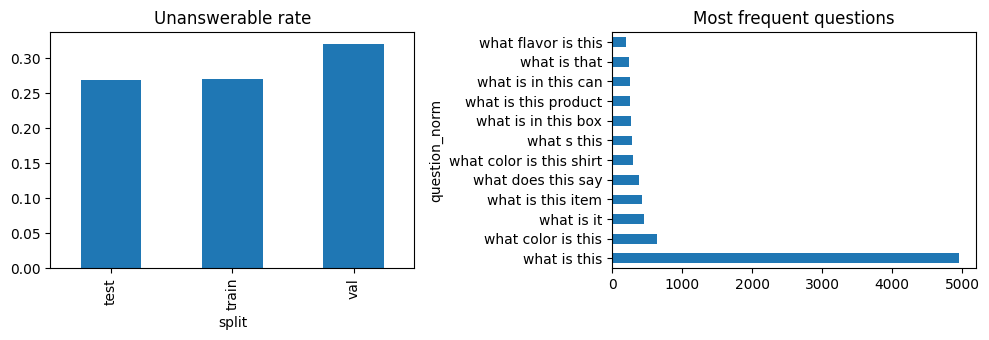

In [ ]:
# Estimate image sharpness for the subgroup analysis.
# Sharpness proxy on resized grayscale images; results are cached to Drive.
quality_file = FEATURES / f"quality_{FINGERPRINT}.csv"
if quality_file.exists():
    quality = pd.read_csv(quality_file)
else:
    from scipy.ndimage import laplace
    sharpness = []
    for path in tqdm(meta.path, desc="Checking image sharpness"):
        try:
            with Image.open(path) as im:
                im = ImageOps.exif_transpose(im).convert("L").resize((128, 128))
                sharpness.append(float(laplace(np.asarray(im, dtype=np.float32)).var()))
        except Exception:
            sharpness.append(np.nan)
    quality = pd.DataFrame({"pair_id": meta.pair_id, "sharpness": sharpness})
    quality.to_csv(quality_file, index=False)
meta = meta.merge(quality, on="pair_id", how="left", validate="one_to_one")
train_median = meta.loc[meta.split == "train", "sharpness"].median()
meta["blur_group"] = np.where(meta.sharpness < train_median, "lower_sharpness", "higher_sharpness")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
meta.groupby("split")["y"].mean().plot.bar(ax=axes[0], title="Unanswerable rate")
meta.question_norm.value_counts().head(12).plot.barh(ax=axes[1], title="Most frequent questions")
plt.tight_layout()
plt.savefig(RESULTS / "data_quality.png", dpi=160)
plt.show()


## 7. Feature extraction

Extract image features with ViT, question features with BERT and joint representations with CLIP.

In [ ]:
# Prepare images and questions for feature extraction.
from torch.utils.data import DataLoader
class ImageDataset(Dataset):
    def __init__(self, paths, mean, std, size=224):
        self.paths = list(paths)
        self.mean = torch.tensor(mean, dtype=torch.float32)[:, None, None]
        self.std = torch.tensor(std, dtype=torch.float32)[:, None, None]
        self.size = size
    def __len__(self): return len(self.paths)
    def __getitem__(self, index):
        with Image.open(self.paths[index]) as im:
            im = ImageOps.exif_transpose(im).convert("RGB").resize(
                (self.size, self.size), Image.Resampling.BICUBIC)
            a = np.asarray(im, dtype=np.float32).copy() / 255.
        x = torch.from_numpy(a).permute(2, 0, 1)
        return (x - self.mean) / self.std

def image_batches(mean, std):
    return DataLoader(ImageDataset(meta.path, mean, std, image_size),
                      batch_size=extract_batch, shuffle=False,
                      num_workers=2, pin_memory=DEVICE.type == "cuda")

def save_arrays(group, arrays):
    for name, array in arrays.items():
        np.save(FEATURES / f"{FINGERPRINT}_{name}.npy", array)
    print(group, "saved:", {k: v.shape for k, v in arrays.items()})

def feature_path(name): return FEATURES / f"{FINGERPRINT}_{name}.npy"
def feature_ready(names): return all(feature_path(name).exists() for name in names)
def free_gpu():
    gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()

def amp_context():
    return torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE.type == "cuda")

timings = {}


In [ ]:
# ViT-B/16 image CLS and 7x7 pooled region tokens.
if not feature_ready(["img_cls", "img_regions"]):
    processor = AutoImageProcessor.from_pretrained(image_model_name)
    vit = AutoModel.from_pretrained(image_model_name).to(DEVICE).eval()
    cls_list, region_list = [], []
    t0 = time.perf_counter()
    with torch.inference_mode():
        for batch in tqdm(image_batches(processor.image_mean, processor.image_std),
                          desc="ViT feature extraction"):
            with amp_context():
                h = vit(pixel_values=batch.to(DEVICE)).last_hidden_state.float()
            cls_list.append(h[:, 0].cpu().numpy().astype(np.float16))
            patches = h[:, 1:]
            side = math.isqrt(patches.shape[1])
            assert side * side == patches.shape[1]
            patches = patches.reshape(len(batch), side, side, -1).permute(0, 3, 1, 2)
            pooled = F.adaptive_avg_pool2d(patches, (7, 7)).flatten(2).transpose(1, 2)
            region_list.append(pooled.cpu().numpy().astype(np.float16))
    save_arrays("ViT", {"img_cls": np.concatenate(cls_list),
                        "img_regions": np.concatenate(region_list)})
    timings["vit_extract_seconds"] = time.perf_counter() - t0
    del vit, processor, cls_list, region_list
    free_gpu()
else:
    print("ViT features already saved; skipping")


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

Fast image processor class <class 'transformers.models.vit.image_processing_vit_fast.ViTImageProcessorFast'> is available for this model. Using slow image processor class. To use the fast image processor class set `use_fast=True`.


model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

ViT feature extraction:   0%|          | 0/1369 [00:00<?, ?it/s]

ViT saved: {'img_cls': (32842, 768), 'img_regions': (32842, 49, 768)}


In [ ]:
# Extract question features using the pretrained BERT model.
# BERT question mean embedding, token embeddings and attention mask.
if not feature_ready(["txt_mean", "txt_tokens", "txt_mask"]):
    tokenizer = AutoTokenizer.from_pretrained(text_model_name)
    bert = AutoModel.from_pretrained(text_model_name).to(DEVICE).eval()
    means, tokens, masks = [], [], []
    t0 = time.perf_counter()
    with torch.inference_mode():
        for start in tqdm(range(0, len(meta), extract_batch * 2),
                          desc="BERT feature extraction"):
            questions = meta.question.iloc[start:start + extract_batch * 2].tolist()
            encoded = tokenizer(questions, padding="max_length", truncation=True,
                                max_length=question_tokens,
                                return_tensors="pt").to(DEVICE)
            with amp_context():
                h = bert(**encoded).last_hidden_state.float()
            mask = encoded["attention_mask"]
            mean = (h * mask.unsqueeze(-1)).sum(1) / mask.sum(1, keepdim=True).clamp(min=1)
            means.append(mean.cpu().numpy().astype(np.float16))
            tokens.append(h.cpu().numpy().astype(np.float16))
            masks.append(mask.cpu().numpy().astype(np.uint8))
    save_arrays("BERT", {"txt_mean": np.concatenate(means),
                         "txt_tokens": np.concatenate(tokens),
                         "txt_mask": np.concatenate(masks)})
    timings["bert_extract_seconds"] = time.perf_counter() - t0
    del bert, tokenizer, means, tokens, masks
    free_gpu()
else:
    print("BERT features already saved; skipping")


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

BERT feature extraction:   0%|          | 0/685 [00:00<?, ?it/s]

BERT saved: {'txt_mean': (32842, 768), 'txt_tokens': (32842, 40, 768), 'txt_mask': (32842, 40)}


In [ ]:
# Extract image and text features using CLIP.
# CLIP frozen image and text features (reference model).
if use_clip and not feature_ready(["clip_img", "clip_txt"]):
    processor = AutoImageProcessor.from_pretrained(clip_model_name)
    tokenizer = AutoTokenizer.from_pretrained(clip_model_name)
    clip = CLIPModel.from_pretrained(clip_model_name).to(DEVICE).eval()
    images, texts = [], []
    t0 = time.perf_counter()
    with torch.inference_mode():
        for batch in tqdm(image_batches(processor.image_mean, processor.image_std),
                          desc="CLIP image features"):
            with amp_context():
                embedding = clip.get_image_features(pixel_values=batch.to(DEVICE))
            if not torch.is_tensor(embedding): embedding = embedding.pooler_output
            images.append(embedding.float().cpu().numpy().astype(np.float16))
        for start in tqdm(range(0, len(meta), extract_batch * 2),
                          desc="CLIP text features"):
            questions = meta.question.iloc[start:start + extract_batch * 2].tolist()
            encoded = tokenizer(questions, padding=True, truncation=True, max_length=77,
                                return_tensors="pt").to(DEVICE)
            with amp_context():
                embedding = clip.get_text_features(**encoded)
            if not torch.is_tensor(embedding): embedding = embedding.pooler_output
            texts.append(embedding.float().cpu().numpy().astype(np.float16))
    save_arrays("CLIP", {"clip_img": np.concatenate(images),
                         "clip_txt": np.concatenate(texts)})
    timings["clip_extract_seconds"] = time.perf_counter() - t0
    del clip, tokenizer, processor, images, texts
    free_gpu()
elif use_clip:
    print("CLIP features already saved; skipping")
(RESULTS / "feature_extraction_times.json").write_text(json.dumps(timings, indent=2))


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

... (4 outputs left out)

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

CLIP text features:   0%|          | 0/685 [00:00<?, ?it/s]

CLIP saved: {'clip_img': (32842, 512), 'clip_txt': (32842, 512)}


137

## 8. Feature preparation

Check feature alignment and prepare the arrays used for model training.

In [ ]:
# Load the saved features and check their shapes.
feature_names = ["img_cls", "img_regions", "txt_mean", "txt_tokens", "txt_mask"]
if use_clip: feature_names += ["clip_img", "clip_txt"]
X = {name: np.load(feature_path(name), mmap_mode="r") for name in feature_names}
for name, array in X.items():
    assert len(array) == len(meta), f"Feature alignment error for {name}"
    print(name, array.shape, array.dtype)
assert meta.pair_id.is_unique
assert meta.loc[meta.split.isin(["train", "val"]), "y"].notna().all()
meta.to_pickle(FEATURES / f"{FINGERPRINT}_metadata.pkl")
idx = {split: np.where(meta.split.to_numpy() == split)[0] for split in ["train", "val", "test"]}
print("Rows:", {k: len(v) for k, v in idx.items()})


img_cls (32842, 768) float16
img_regions (32842, 49, 768) float16
txt_mean (32842, 768) float16
txt_tokens (32842, 40, 768) float16
txt_mask (32842, 40) uint8
clip_img (32842, 512) float16
clip_txt (32842, 512) float16
Rows: {'train': 20523, 'val': 4319, 'test': 8000}


## 9. Model architectures

Define question-only, image-only, early fusion, cross-attention, gated fusion and CLIP-based classifiers.

In [ ]:
# Define the baseline models and fusion models.
class MLP(nn.Module):
    def __init__(self, in_dim, hidden=256, dropout=0.25):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(),
                                 nn.Dropout(dropout), nn.Linear(hidden, 1))
    def forward(self, x): return self.net(x).squeeze(-1)

class QuestionOnly(nn.Module):
    def __init__(self, text_dim=768):
        super().__init__(); self.head = MLP(text_dim)
    def forward(self, b): return self.head(b["txt_mean"])

class ImageOnly(nn.Module):
    def __init__(self, image_dim=768):
        super().__init__(); self.head = MLP(image_dim)
    def forward(self, b): return self.head(b["img_cls"])

class EarlyFusion(nn.Module):
    def __init__(self, image_dim=768, text_dim=768):
        super().__init__(); self.head = MLP(image_dim + text_dim)
    def forward(self, b): return self.head(torch.cat([b["img_cls"], b["txt_mean"]], dim=-1))

class CrossAttention(nn.Module):
    def __init__(self, dim=768, hidden=128):
        super().__init__()
        self.text_proj = nn.Linear(dim, hidden)
        self.image_proj = nn.Linear(dim, hidden)
        self.attention = nn.MultiheadAttention(hidden, num_heads=4, batch_first=True)
        self.head = MLP(hidden * 2, hidden)
    def forward(self, b):
        text = self.text_proj(b["txt_tokens"])
        image = self.image_proj(b["img_regions"])
        attended, _ = self.attention(query=text, key=image, value=image,
                                     need_weights=False)
        mask = b["txt_mask"].unsqueeze(-1).float()
        attended = (attended * mask).sum(1) / mask.sum(1).clamp(min=1)
        text_pool = (text * mask).sum(1) / mask.sum(1).clamp(min=1)
        return self.head(torch.cat([text_pool, attended], dim=-1))

class GatedFusion(nn.Module):
    def __init__(self, image_dim=768, text_dim=768, hidden=256, modality_dropout=0.15):
        super().__init__()
        self.image = nn.Sequential(nn.Linear(image_dim, hidden), nn.ReLU())
        self.text = nn.Sequential(nn.Linear(text_dim, hidden), nn.ReLU())
        self.gate = nn.Linear(hidden * 2, hidden)
        self.head = MLP(hidden, hidden)
        self.modality_dropout = modality_dropout
    def forward(self, b):
        i, t = self.image(b["img_cls"]), self.text(b["txt_mean"])
        if self.training and self.modality_dropout:
            drop_i = (torch.rand(len(i), 1, device=i.device) < self.modality_dropout)
            drop_t = (torch.rand(len(t), 1, device=t.device) < self.modality_dropout)
            # Never remove both modalities from the same example.
            drop_t = drop_t & ~drop_i
            i = i.masked_fill(drop_i, 0)
            t = t.masked_fill(drop_t, 0)
        gate = torch.sigmoid(self.gate(torch.cat([i, t], -1)))
        return self.head(gate * i + (1 - gate) * t)

class CLIPEarlyFusion(nn.Module):
    def __init__(self, image_dim=512, text_dim=512):
        super().__init__(); self.head = MLP(image_dim + text_dim)
    def forward(self, b): return self.head(torch.cat([b["clip_img"], b["clip_txt"]], -1))

MODEL_INPUTS = {
    "question_only": ["txt_mean"],
    "image_only": ["img_cls"],
    "early": ["img_cls", "txt_mean"],
    "cross_attention": ["txt_tokens", "txt_mask", "img_regions"],
    "gated": ["img_cls", "txt_mean"],
    "clip_early": ["clip_img", "clip_txt"],
}
MODEL_BUILDERS = {
    "question_only": QuestionOnly, "image_only": ImageOnly, "early": EarlyFusion,
    "cross_attention": CrossAttention, "gated": GatedFusion,
    "clip_early": lambda: CLIPEarlyFusion(X["clip_img"].shape[-1], X["clip_txt"].shape[-1]),
}
MODEL_NAMES = ["question_only", "image_only", "early", "cross_attention", "gated"]
if use_clip: MODEL_NAMES.append("clip_early")
print("Models:", MODEL_NAMES, "+ late fusion (validation-tuned)")


Models: ['question_only', 'image_only', 'early', 'cross_attention', 'gated', 'clip_early'] + late fusion (validation-tuned)


## 10. Training and evaluation functions

Prepare the data loaders, model training loop, validation and evaluation functions.

In [ ]:
# Set up training, validation and evaluation functions.
class FeatureDataset(Dataset):
    def __init__(self, indices, feature_names, require_labels=True):
        self.indices = np.asarray(indices)
        self.names = feature_names
        self.require_labels = require_labels
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        row = int(self.indices[i])
        data = {k: torch.as_tensor(np.asarray(X[k][row]).copy(),
                                   dtype=torch.float32) for k in self.names}
        y = meta.y.iloc[row]
        data["y"] = torch.tensor(float(y) if pd.notna(y) else -1.0,
                                  dtype=torch.float32)
        data["row"] = torch.tensor(row, dtype=torch.long)
        return data

def loader(split, names, shuffle=False):
    return DataLoader(FeatureDataset(idx[split], names),
                      batch_size=train_batch, shuffle=shuffle,
                      num_workers=0, pin_memory=DEVICE.type == "cuda")

def to_device(batch):
    return {key: value.to(DEVICE, non_blocking=True) for key, value in batch.items()}

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def evaluate_loader(model, data_loader):
    model.eval()
    all_rows, all_y, all_p = [], [], []
    with torch.inference_mode():
        for batch in data_loader:
            batch = to_device(batch)
            p = torch.sigmoid(model(batch)).cpu().numpy()
            all_p.extend(p)
            all_y.extend(batch["y"].cpu().numpy())
            all_rows.extend(batch["row"].cpu().numpy())
    return pd.DataFrame({"row": all_rows, "y": all_y, "p": all_p})

def best_threshold(y, p):
    thresholds = np.linspace(0.05, 0.95, 181)
    return float(max(thresholds, key=lambda t: f1_score(
        y, p >= t, average="macro", zero_division=0)))

def train_model(name, seed):
    folder = RUNS / name / f"seed_{seed}"
    folder.mkdir(parents=True, exist_ok=True)
    predictions_file = folder / "predictions.csv"
    if predictions_file.exists():
        print("Already completed:", name, seed)
        return pd.read_csv(predictions_file)
    set_seed(seed)
    names = MODEL_INPUTS[name]
    model = MODEL_BUILDERS[name]().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate,
                                  weight_decay=weight_decay)
    criterion = nn.BCEWithLogitsLoss()
    train_dl, val_dl = loader("train", names, True), loader("val", names)
    best_loss, best_epoch, wait = float("inf"), -1, 0
    history = []
    t0 = time.perf_counter()
    best_file = folder / "best_model.pt"
    for epoch in range(epochs):
        model.train()
        total_loss, seen = 0.0, 0
        for batch in train_dl:
            batch = to_device(batch)
            optimizer.zero_grad(set_to_none=True)
            logits = model(batch)
            loss = criterion(logits, batch["y"])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item() * len(logits)
            seen += len(logits)
        train_loss = total_loss / seen
        val = evaluate_loader(model, val_dl)
        val_p = np.clip(val.p.to_numpy(), 1e-6, 1 - 1e-6)
        val_y = val.y.to_numpy()
        val_loss = float(-(val_y * np.log(val_p) +
                           (1 - val_y) * np.log(1 - val_p)).mean())
        history.append({"epoch": epoch + 1, "train_loss": train_loss,
                        "val_loss": val_loss,
                        "val_macro_f1_at_0_5": f1_score(val_y, val_p >= 0.5,
                                                       average="macro", zero_division=0)})
        print(f"{name} seed {seed} epoch {epoch + 1}: "
              f"train {train_loss:.4f} val {val_loss:.4f}", flush=True)
        if val_loss < best_loss - 1e-4:
            best_loss, best_epoch, wait = val_loss, epoch + 1, 0
            torch.save(model.state_dict(), best_file)
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(torch.load(best_file, map_location=DEVICE, weights_only=True))
    val_pred = evaluate_loader(model, val_dl)
    threshold = best_threshold(val_pred.y.to_numpy(), val_pred.p.to_numpy())
    pieces = []
    for split in ["train", "val", "test"]:
        frame = evaluate_loader(model, loader(split, names))
        frame["split"], frame["model"], frame["seed"] = split, name, seed
        frame["threshold"] = threshold
        frame["pair_id"] = meta.pair_id.iloc[frame.row.to_numpy()].to_numpy()
        frame.loc[frame.y < 0, "y"] = np.nan
        pieces.append(frame)
    predictions = pd.concat(pieces, ignore_index=True)
    predictions.to_csv(predictions_file, index=False)
    pd.DataFrame(history).to_csv(folder / "history.csv", index=False)
    summary = {"model": name, "seed": seed, "best_epoch": best_epoch,
               "train_seconds": round(time.perf_counter() - t0, 2),
               "trainable_parameters": sum(p.numel() for p in model.parameters()
                                           if p.requires_grad),
               "threshold": threshold}
    (folder / "summary.json").write_text(json.dumps(summary, indent=2))
    del model, optimizer
    free_gpu()
    return predictions


## 11. Model checks

Check model outputs and gradients using sample feature tensors.

In [ ]:
# Run a small test to check that the models work.
def smoke_test_models():
    fake = {
        "img_cls": torch.randn(3, 768, device=DEVICE),
        "txt_mean": torch.randn(3, 768, device=DEVICE),
        "img_regions": torch.randn(3, 49, 768, device=DEVICE),
        "txt_tokens": torch.randn(3, 40, 768, device=DEVICE),
        "txt_mask": torch.ones(3, 40, device=DEVICE),
        "clip_img": torch.randn(3, 512, device=DEVICE),
        "clip_txt": torch.randn(3, 512, device=DEVICE),
    }
    for name in MODEL_NAMES:
        model = MODEL_BUILDERS[name]().to(DEVICE)
        out = model(fake)
        assert out.shape == (3,), (name, out.shape)
        out.mean().backward()
        assert any(p.grad is not None for p in model.parameters()), name
        print(name, "PASS")
        del model
    free_gpu()
smoke_test_models()


question_only PASS
image_only PASS
early PASS
cross_attention PASS
gated PASS
clip_early PASS


## 12. Model training

Train the classifiers across three random seeds and save their best checkpoints.

In [ ]:
# Train each model with three random seeds.
prediction_frames = []
for name in MODEL_NAMES:
    for seed in seeds:
        print("\nTRAINING", name, "SEED", seed)
        prediction_frames.append(train_model(name, seed))
print("Completed trained model-seed runs:", len(prediction_frames))



TRAINING question_only SEED 0
question_only seed 0 epoch 1: train 0.5363 val 0.5609
question_only seed 0 epoch 2: train 0.5171 val 0.5688
question_only seed 0 epoch 3: train 0.5093 val 0.5536
question_only seed 0 epoch 4: train 0.5067 val 0.5499
question_only seed 0 epoch 5: train 0.5035 val 0.5592
question_only seed 0 epoch 6: train 0.5006 val 0.5701
question_only seed 0 epoch 7: train 0.4978 val 0.5739

TRAINING question_only SEED 1
question_only seed 1 epoch 1: train 0.5394 val 0.5643
question_only seed 1 epoch 2: train 0.5140 val 0.5609
question_only seed 1 epoch 3: train 0.5086 val 0.5609
question_only seed 1 epoch 4: train 0.5083 val 0.5615
question_only seed 1 epoch 5: train 0.5049 val 0.5582
question_only seed 1 epoch 6: train 0.5005 val 0.5494
question_only seed 1 epoch 7: train 0.4977 val 0.5502
question_only seed 1 epoch 8: train 0.4952 val 0.5483
question_only seed 1 epoch 9: train 0.4922 val 0.5615
question_only seed 1 epoch 10: train 0.4919 val 0.5687
question_only seed 

## 13. Late fusion

Combine the question-only and image-only predictions using validation-selected weights.

In [ ]:
# Combine the two baseline predictions for late fusion.
for seed in seeds:
    outdir = RUNS / "late" / f"seed_{seed}"
    outdir.mkdir(parents=True, exist_ok=True)
    outpath = outdir / "predictions.csv"
    if outpath.exists():
        prediction_frames.append(pd.read_csv(outpath))
        continue
    q = pd.read_csv(RUNS / "question_only" / f"seed_{seed}" / "predictions.csv")
    i = pd.read_csv(RUNS / "image_only" / f"seed_{seed}" / "predictions.csv")
    merged = q[["pair_id", "split", "row", "y", "p"]].merge(
        i[["pair_id", "split", "p"]], on=["pair_id", "split"],
        suffixes=("_q", "_i"), validate="one_to_one")
    dev = merged[merged.split == "val"]
    candidates = []
    for weight in np.linspace(0, 1, 21):
        prob = weight * dev.p_q + (1 - weight) * dev.p_i
        threshold = best_threshold(dev.y.to_numpy(), prob.to_numpy())
        score = f1_score(dev.y, prob >= threshold, average="macro", zero_division=0)
        candidates.append((score, float(weight), threshold))
    score, weight, threshold = max(candidates)
    merged["p"] = weight * merged.p_q + (1 - weight) * merged.p_i
    merged["model"], merged["seed"], merged["threshold"] = "late", seed, threshold
    result = merged[["row", "y", "p", "split", "model", "seed",
                     "threshold", "pair_id"]]
    result.to_csv(outpath, index=False)
    (outdir / "summary.json").write_text(json.dumps(
        {"model": "late", "seed": seed, "image_weight": 1 - weight,
         "question_weight": weight, "threshold": threshold,
         "val_macro_f1": score}, indent=2))
    prediction_frames.append(result)
print("Late fusion complete")


Late fusion complete


## 14. Model evaluation

Calculate classification metrics and compare performance across the dataset splits.

In [ ]:
# Calculate and save the evaluation results.
predictions = pd.concat(prediction_frames, ignore_index=True)
predictions.to_csv(RESULTS / "all_predictions.csv", index=False)
metric_rows = []
for (name, seed, split), part in predictions.groupby(["model", "seed", "split"]):
    labeled = part[part.y.notna()]
    if labeled.empty:
        continue
    y = labeled.y.astype(int).to_numpy()
    p = labeled.p.to_numpy()
    pred = (p >= labeled.threshold.iloc[0]).astype(int)
    metric_rows.append({
        "model": name, "seed": seed, "split": split, "n": len(y),
        "threshold": float(labeled.threshold.iloc[0]),
        "accuracy": accuracy_score(y, pred),
        "balanced_accuracy": balanced_accuracy_score(y, pred),
        "macro_f1": f1_score(y, pred, average="macro", zero_division=0),
        "precision_unanswerable": precision_score(y, pred, zero_division=0),
        "recall_unanswerable": recall_score(y, pred, zero_division=0),
        "auroc": roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan,
        "auprc": average_precision_score(y, p) if len(np.unique(y)) == 2 else np.nan,
        "brier": brier_score_loss(y, p)
    })
metrics = pd.DataFrame(metric_rows)
metrics.to_csv(RESULTS / "metrics_by_seed.csv", index=False)
display(metrics.sort_values(["split", "macro_f1"], ascending=[True, False]).round(4))
if "test" not in metrics.split.values:
    print("IMPORTANT: Official test labels unavailable. Do not claim test F1 or AUPRC.")


,model,seed,split,n,threshold,accuracy,balanced_accuracy,macro_f1,precision_unanswerable,recall_unanswerable,auroc,auprc,brier
3,clip_early,1,test,8000,0.470,0.8436,0.8020,0.8013,0.7072,0.7122,0.9021,0.7824,0.1090
6,clip_early,2,test,8000,0.405,0.8381,0.8046,0.7981,0.6859,0.7322,0.8987,0.7759,0.1104
0,clip_early,0,test,8000,0.495,0.8436,0.7924,0.7974,0.7205,0.6819,0.8992,0.7765,0.1103
21,early,1,test,8000,0.440,0.8111,0.7737,0.7660,0.6359,0.6931,0.8699,0.7288,0.1244
24,early,2,test,8000,0.450,0.8102,0.7726,0.7649,0.6345,0.6912,0.8682,0.7289,0.1262
...,...,...,...,...,...,...,...,...,...,...,...,...,...
38,image_only,0,val,4319,0.370,0.7279,0.6932,0.6911,0.5728,0.5964,0.7668,0.6225,0.1745
44,image_only,2,val,4319,0.360,0.7226,0.6937,0.6888,0.5619,0.6130,0.7623,0.6089,0.1763
59,question_only,1,val,4319,0.400,0.7083,0.6597,0.6614,0.5471,0.5242,0.7335,0.5638,0.1849
56,question_only,0,val,4319,0.400,0.7136,0.6539,0.6587,0.5616,0.4874,0.7311,0.5630,0.1855


,split,model,macro_f1_mean,macro_f1_sd,auroc_mean,auprc_mean,brier_mean
0,test,clip_early,0.7990,0.0021,0.9000,0.7783,0.1099
1,test,cross_attention,0.7613,0.0018,0.8618,0.7132,0.1295
2,test,early,0.7617,0.0064,0.8663,0.7235,0.1267
3,test,gated,0.7540,0.0010,0.8600,0.7113,0.1287
4,test,image_only,0.6946,0.0046,0.7737,0.5932,0.1555
5,test,late,0.7409,0.0013,0.8459,0.6828,0.1458
6,test,question_only,0.6568,0.0035,0.7447,0.5256,0.1670
7,train,clip_early,0.8636,0.0195,0.9493,0.8849,0.0782
8,train,cross_attention,0.8129,0.0127,0.9115,0.8214,0.1034
9,train,early,0.8308,0.0284,0.9241,0.8354,0.0968


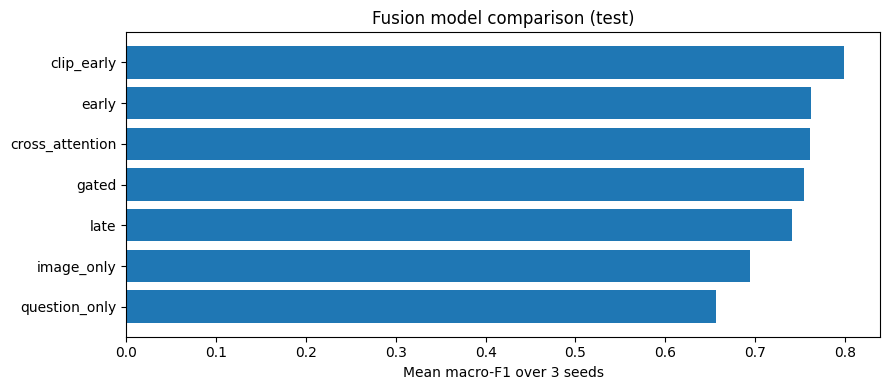

In [ ]:
# Summarise the average results across the three seeds.
aggregate = metrics.groupby(["split", "model"]).agg(
    macro_f1_mean=("macro_f1", "mean"),
    macro_f1_sd=("macro_f1", "std"),
    auroc_mean=("auroc", "mean"),
    auprc_mean=("auprc", "mean"),
    brier_mean=("brier", "mean")
).reset_index()
aggregate.to_csv(RESULTS / "model_comparison.csv", index=False)
display(aggregate.round(4))
split_to_plot = "test" if "test" in metrics.split.values else "val"
plot_df = aggregate[aggregate.split == split_to_plot].sort_values("macro_f1_mean")
plt.figure(figsize=(9, 4))
plt.barh(plot_df.model, plot_df.macro_f1_mean)
plt.xlabel("Mean macro-F1 over 3 seeds")
plt.title(f"Fusion model comparison ({split_to_plot})")
plt.tight_layout()
plt.savefig(RESULTS / "model_comparison.png", dpi=170)
plt.show()


## 15. Confidence intervals

Estimate paired bootstrap confidence intervals for improvements over the unimodal baseline.

In [ ]:
# Use bootstrap samples to estimate confidence intervals.
rng = np.random.default_rng(2026)
boot_rows = []
for split in ["val", "test"]:
    for seed in seeds:
        dev = metrics[(metrics.split == "val") & (metrics.seed == seed) &
                      metrics.model.isin(["question_only", "image_only"])]
        if dev.empty: continue
        baseline = dev.sort_values("macro_f1", ascending=False).iloc[0].model
        a = predictions[(predictions.split == split) & (predictions.seed == seed) &
                        (predictions.model == baseline) & predictions.y.notna()]
        for name in ["early", "late", "cross_attention", "gated", "clip_early"]:
            b = predictions[(predictions.split == split) & (predictions.seed == seed) &
                            (predictions.model == name) & predictions.y.notna()]
            if a.empty or b.empty: continue
            paired = a[["pair_id", "y", "p", "threshold"]].merge(
                b[["pair_id", "y", "p", "threshold"]],
                on=["pair_id", "y"], suffixes=("_base", "_fusion"),
                validate="one_to_one")
            y = paired.y.astype(int).to_numpy()
            pred_a = (paired.p_base >= paired.threshold_base).astype(int).to_numpy()
            pred_b = (paired.p_fusion >= paired.threshold_fusion).astype(int).to_numpy()
            gains = []
            for _ in range(500):
                sample = rng.integers(0, len(y), len(y))
                gains.append(f1_score(y[sample], pred_b[sample],
                                      average="macro", zero_division=0) -
                             f1_score(y[sample], pred_a[sample],
                                      average="macro", zero_division=0))
            boot_rows.append({"split": split, "seed": seed, "baseline": baseline,
                              "fusion": name, "macro_f1_gain": float(np.mean(gains)),
                              "ci_low": float(np.quantile(gains, 0.025)),
                              "ci_high": float(np.quantile(gains, 0.975))})
bootstrap = pd.DataFrame(boot_rows)
bootstrap.to_csv(RESULTS / "paired_bootstrap.csv", index=False)
display(bootstrap.round(4) if not bootstrap.empty else "No paired labeled results.")


,split,seed,baseline,fusion,macro_f1_gain,ci_low,ci_high
0,val,0,image_only,early,0.0677,0.0539,0.0815
1,val,0,image_only,late,0.0480,0.0343,0.0625
2,val,0,image_only,cross_attention,0.0723,0.0571,0.0886
3,val,0,image_only,gated,0.0617,0.0466,0.0766
4,val,0,image_only,clip_early,0.0984,0.0813,0.1152
5,val,1,image_only,early,0.0698,0.0531,0.0843
6,val,1,image_only,late,0.0410,0.0284,0.0545
7,val,1,image_only,cross_attention,0.0676,0.0529,0.0810
8,val,1,image_only,gated,0.0652,0.0510,0.0797
9,val,1,image_only,clip_early,0.0954,0.0771,0.1130


## 16. Training curves and efficiency

Plot learning curves and summarise model parameters and training time.

In [ ]:
# Summarise training time and model efficiency.
efficiency_rows = []
for name in MODEL_NAMES:
    for seed in seeds:
        folder = RUNS / name / f"seed_{seed}"
        hist = pd.read_csv(folder / "history.csv")
        info = json.loads((folder / "summary.json").read_text())
        efficiency_rows.append(info)
        fig, ax = plt.subplots(figsize=(5, 3))
        ax.plot(hist.epoch, hist.train_loss, label="Train")
        ax.plot(hist.epoch, hist.val_loss, label="Validation")
        ax.set(title=f"{name}, seed {seed}", xlabel="Epoch", ylabel="BCE loss")
        ax.legend()
        fig.tight_layout()
        fig.savefig(RESULTS / f"loss_{name}_{seed}.png", dpi=140)
        plt.close(fig)
efficiency = pd.DataFrame(efficiency_rows)
efficiency.to_csv(RESULTS / "training_efficiency.csv", index=False)
display(efficiency.groupby("model").agg(
    train_seconds_mean=("train_seconds", "mean"),
    trainable_parameters=("trainable_parameters", "first"),
    best_epoch_mean=("best_epoch", "mean")).round(1))


,train_seconds_mean,trainable_parameters,best_epoch_mean
model,,,
clip_early,22.9,262657,8.0
cross_attention,65.5,295937,5.3
early,25.3,393729,8.7
gated,14.9,591105,3.0
image_only,12.3,197121,3.3
question_only,15.1,197121,5.3


### Training and validation comparison

Compare training and validation macro-F1 to examine generalisation gaps.

,train_f1,val_f1,mean_gap
model,,,
clip_early,0.8636,0.7914,0.0721
early,0.8308,0.7641,0.0666
gated,0.8170,0.7555,0.0615
cross_attention,0.8129,0.7626,0.0503
image_only,0.7403,0.6918,0.0485
late,0.7816,0.7363,0.0453
question_only,0.6659,0.6579,0.0081


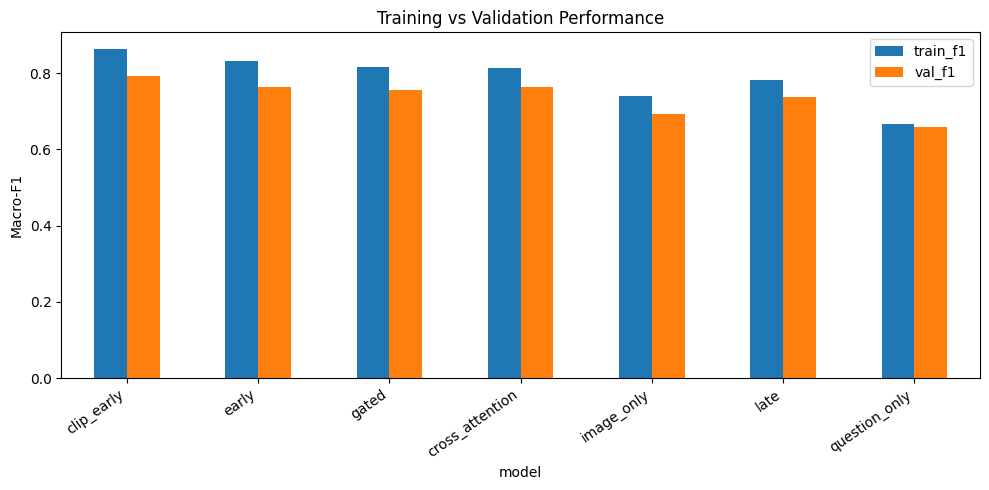

In [ ]:
# Compare training and validation scores to check overfitting.
# Compare training and validation performance
comparison = metrics[
    metrics["split"].isin(["train", "val"])
].pivot_table(
    index=["model", "seed"],
    columns="split",
    values="macro_f1"
).reset_index()

comparison["f1_gap"] = comparison["train"] - comparison["val"]

overfitting = comparison.groupby("model").agg(
    train_f1=("train", "mean"),
    val_f1=("val", "mean"),
    mean_gap=("f1_gap", "mean")
).sort_values("mean_gap", ascending=False)

display(overfitting.round(4))

overfitting.to_csv(RESULTS / "overfitting_analysis.csv")

overfitting[["train_f1", "val_f1"]].plot(
    kind="bar", figsize=(10, 5)
)
plt.ylabel("Macro-F1")
plt.title("Training vs Validation Performance")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(RESULTS / "overfitting_comparison.png", dpi=150)
plt.show()


## 17. Prediction errors

Plot the confusion matrix and inspect examples of incorrect predictions.

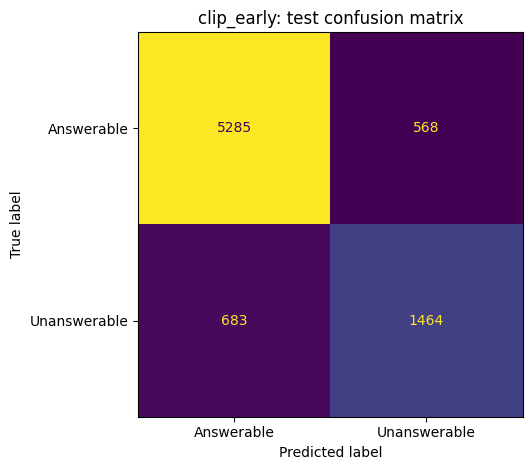

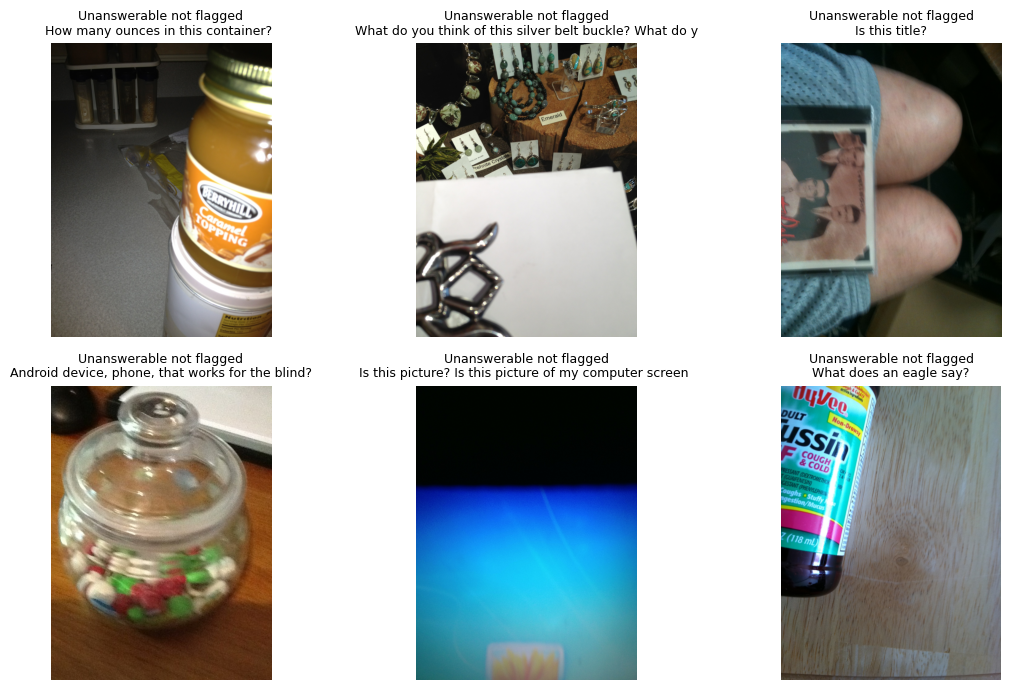

In [ ]:
# Show the confusion matrix and some prediction errors.
best_fusion = metrics[(metrics.split == "val") &
    metrics.model.isin(["early", "late", "cross_attention", "gated", "clip_early"])
].groupby("model").macro_f1.mean().idxmax()
view_split = "test" if "test" in metrics.split.values else "val"
selected = predictions[(predictions.model == best_fusion) &
                       (predictions.seed == seeds[0]) &
                       (predictions.split == view_split) &
                       predictions.y.notna()].copy()
selected["pred"] = (selected.p >= selected.threshold).astype(int)
ConfusionMatrixDisplay.from_predictions(selected.y.astype(int), selected.pred,
                                        display_labels=["Answerable", "Unanswerable"],
                                        colorbar=False)
plt.title(f"{best_fusion}: {view_split} confusion matrix")
plt.tight_layout()
plt.savefig(RESULTS / "confusion_matrix.png", dpi=160)
plt.show()
errors = selected[selected.pred != selected.y.astype(int)].copy()
errors = errors.merge(meta[["pair_id", "question", "path", "blur_group"]],
                      on="pair_id", validate="one_to_one")
errors["error_type"] = np.where(errors.y == 0, "Wrongly withheld help",
                                "Unanswerable not flagged")
errors.to_csv(RESULTS / "failure_cases.csv", index=False)
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, (_, item) in zip(axes.ravel(), errors.head(6).iterrows()):
    with Image.open(item.path) as im:
        ax.imshow(ImageOps.exif_transpose(im).convert("RGB"))
    ax.set_title(f"{item.error_type}\n{item.question[:55]}", fontsize=9)
    ax.axis("off")
for ax in axes.ravel()[min(6, len(errors)):]: ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS / "failure_gallery.png", dpi=150)
plt.show()


## 18. Subgroup analysis

Compare model performance across image sharpness, question frequency and answer types.

### Detailed subgroup metrics

Report class counts, accuracy, unanswerable recall and false-positive rates. Macro-F1 is omitted for single-class groups.

In [ ]:
# Compare results across different data subgroups.
# Additional subgroup evaluation
subgroup_results = []

for (model, seed_value, split), group in predictions[
    predictions["y"].notna()
].groupby(["model", "seed", "split"]):

    data = group.merge(
        meta[["pair_id", "blur_group", "rare_question", "answer_type"]],
        on="pair_id",
        validate="one_to_one"
    )

    for column in ["blur_group", "rare_question", "answer_type"]:
        for category, part in data.groupby(column):
            if len(part) < 30:
                continue

            y_true = part["y"].astype(int).to_numpy()
            y_pred = (part["p"] >= part["threshold"]).astype(int).to_numpy()

            tn, fp, fn, tp = confusion_matrix(
                y_true, y_pred, labels=[0, 1]
            ).ravel()

            subgroup_results.append({
                "model": model,
                "seed": seed_value,
                "split": split,
                "subgroup": column,
                "category": str(category),
                "n": len(part),
                "answerable": int((y_true == 0).sum()),
                "unanswerable": int((y_true == 1).sum()),
                "accuracy": accuracy_score(y_true, y_pred),
                "macro_f1": (
                    f1_score(y_true, y_pred, average="macro")
                    if len(np.unique(y_true)) == 2 else np.nan
                ),
                "unanswerable_recall": tp / (tp + fn) if tp + fn else np.nan,
                "false_positive_rate": fp / (fp + tn) if fp + tn else np.nan
            })

subgroup_details = pd.DataFrame(subgroup_results)
subgroup_details.to_csv(
    RESULTS / "subgroup_detailed.csv", index=False
)

display(subgroup_details[
    (subgroup_details["model"] == best_fusion) &
    (subgroup_details["split"] == "test")
].round(3))


,model,seed,split,subgroup,category,n,answerable,unanswerable,accuracy,macro_f1,unanswerable_recall,false_positive_rate
0,clip_early,0,test,blur_group,higher_sharpness,3908,3202,706,0.864,0.752,0.530,0.062
1,clip_early,0,test,blur_group,lower_sharpness,4092,2651,1441,0.824,0.808,0.756,0.139
2,clip_early,0,test,rare_question,False,4306,3448,858,0.885,0.817,0.690,0.066
3,clip_early,0,test,rare_question,True,3694,2405,1289,0.795,0.771,0.676,0.141
4,clip_early,0,test,answer_type,number,123,123,0,0.813,NaN,NaN,0.187
5,clip_early,0,test,answer_type,other,5381,5381,0,0.914,NaN,NaN,0.086
6,clip_early,0,test,answer_type,unanswerable,2147,0,2147,0.682,NaN,0.682,NaN
7,clip_early,0,test,answer_type,yes/no,349,349,0,0.768,NaN,NaN,0.232
24,clip_early,1,test,blur_group,higher_sharpness,3908,3202,706,0.858,0.757,0.589,0.082
25,clip_early,1,test,blur_group,lower_sharpness,4092,2651,1441,0.829,0.814,0.772,0.140


## 19. Decision threshold analysis

Examine how different classification thresholds affect false positives and false negatives.

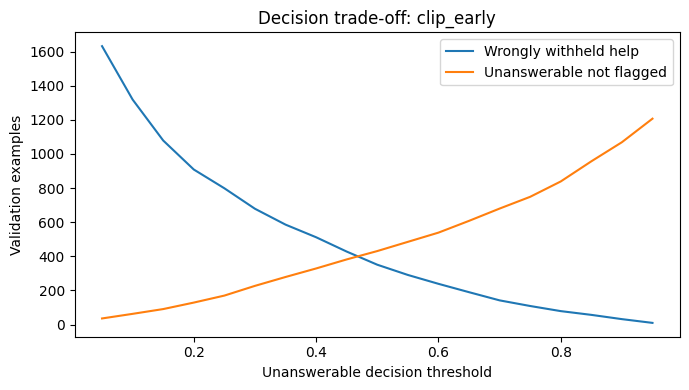

In [ ]:
# Check how changing the threshold affects prediction errors.
tradeoff_rows = []
for name, part in predictions[(predictions.split == "val") &
                               (predictions.seed == seeds[0])].groupby("model"):
    y = part.y.astype(int).to_numpy()
    p = part.p.to_numpy()
    for t in np.linspace(0.05, 0.95, 19):
        tn, fp, fn, tp = confusion_matrix(y, p >= t, labels=[0, 1]).ravel()
        tradeoff_rows.append({"model": name, "threshold": t,
                              "wrongly_withheld_help": int(fp),
                              "unanswerable_not_flagged": int(fn),
                              "macro_f1": f1_score(y, p >= t, average="macro",
                                                   zero_division=0)})
tradeoffs = pd.DataFrame(tradeoff_rows)
tradeoffs.to_csv(RESULTS / "threshold_tradeoffs.csv", index=False)
part = tradeoffs[tradeoffs.model == best_fusion]
plt.figure(figsize=(7, 4))
plt.plot(part.threshold, part.wrongly_withheld_help, label="Wrongly withheld help")
plt.plot(part.threshold, part.unanswerable_not_flagged,
         label="Unanswerable not flagged")
plt.xlabel("Unanswerable decision threshold")
plt.ylabel("Validation examples")
plt.legend()
plt.title(f"Decision trade-off: {best_fusion}")
plt.tight_layout()
plt.savefig(RESULTS / "threshold_tradeoff.png", dpi=160)
plt.show()


## 20. Classifier inference time

Measure classifier-head inference time using cached features, excluding image and text preprocessing and pretrained encoder computation.

In [ ]:
# Measure prediction time using saved features.
latency_rows = []
for name in MODEL_NAMES:
    model = MODEL_BUILDERS[name]().to(DEVICE).eval()
    model.load_state_dict(torch.load(RUNS / name /
        f"seed_{seeds[0]}" / "best_model.pt",
        map_location=DEVICE, weights_only=True))
    example = next(iter(loader("val", MODEL_INPUTS[name])))
    example = to_device({k: v[:1] for k, v in example.items()})
    with torch.inference_mode():
        for _ in range(5): model(example)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        times = []
        for _ in range(50):
            if DEVICE.type == "cuda": torch.cuda.synchronize()
            t0 = time.perf_counter()
            model(example)
            if DEVICE.type == "cuda": torch.cuda.synchronize()
            times.append((time.perf_counter() - t0) * 1000)
    latency_rows.append({"model": name, "head_latency_ms_median": np.median(times),
                         "head_latency_ms_p95": np.percentile(times, 95)})
    del model
latency = pd.DataFrame(latency_rows)
latency.to_csv(RESULTS / "head_latency.csv", index=False)
display(latency.round(3))
free_gpu()


,model,head_latency_ms_median,head_latency_ms_p95
0,question_only,0.178,0.274
1,image_only,0.170,0.214
2,early,0.200,0.252
3,cross_attention,0.792,0.922
4,gated,0.426,0.482
5,clip_early,0.196,0.237


### End-to-end inference time

Measure single-example CLIP early-fusion latency including image loading, preprocessing, CLIP encoding and classification. This uses a separate preprocessing path from cached feature extraction and excludes network or deployment overhead.

In [ ]:
# Measure CLIP prediction time from image loading to output.
# End-to-end latency for CLIP early fusion
from transformers import CLIPProcessor

clip_processor = CLIPProcessor.from_pretrained(clip_model_name)
clip_encoder = CLIPModel.from_pretrained(clip_model_name).to(DEVICE).eval()

classifier = MODEL_BUILDERS["clip_early"]().to(DEVICE).eval()
classifier.load_state_dict(
    torch.load(
        RUNS / "clip_early" / f"seed_{seeds[0]}" / "best_model.pt",
        map_location=DEVICE,
        weights_only=True
    )
)

# Select 50 validation examples
samples = meta[meta["split"] == "val"].sample(
    n=50, random_state=42
)

times = []

with torch.inference_mode():
    for _, sample in tqdm(samples.iterrows(), total=len(samples)):
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()

        with Image.open(sample["path"]) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")

            inputs = clip_processor(
                text=[sample["question"]],
                images=image,
                return_tensors="pt",
                padding=True,
                truncation=True
            ).to(DEVICE)

        image_features = clip_encoder.get_image_features(
            pixel_values=inputs["pixel_values"]
        )
        text_features = clip_encoder.get_text_features(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"]
        )

        if not torch.is_tensor(image_features):
            image_features = image_features.pooler_output
        if not torch.is_tensor(text_features):
            text_features = text_features.pooler_output

        classifier({
            "clip_img": image_features.float(),
            "clip_txt": text_features.float()
        })

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        times.append((time.perf_counter() - start) * 1000)

latency_result = pd.DataFrame([{
    "model": "clip_early",
    "samples": len(times),
    "median_ms": np.median(times),
    "p95_ms": np.percentile(times, 95),
    "mean_ms": np.mean(times)
}])

display(latency_result.round(2))
latency_result.to_csv(
    RESULTS / "end_to_end_latency.csv", index=False
)

del clip_encoder, classifier
free_gpu()


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


  0%|          | 0/50 [00:00<?, ?it/s]

,model,samples,median_ms,p95_ms,mean_ms
0,clip_early,50,52.68,130.62,57.59


## 21. Experiment summary

Save the model settings and evaluation outputs for reproducibility.

In [ ]:
# Save the experiment settings and final summary.
run_info = {
    "project": "MMA Assignment 2.2 - independent implementation",
    "dataset": "VizWiz-VQA",
    "label": "1 = unanswerable; 0 = answerable",
    "fingerprint": FINGERPRINT,
    "fast_check": fast_check,
    "split_sizes": {s: int(len(idx[s])) for s in idx},
    "test_labels_verified": bool(meta.loc[meta.split == "test", "y"].notna().all()),
    "seeds": seeds,
    "models": MODEL_NAMES + ["late"],
    "device": str(DEVICE),
    "torch_version": torch.__version__,
    "transformers_version": __import__("transformers").__version__,
    "training_settings": {"epochs": epochs, "batch_size": train_batch, "learning_rate": learning_rate},
}
(RESULTS / "reproducibility.json").write_text(json.dumps(run_info, indent=2))
print("All outputs saved to:", RESULTS)
print("Full dataset run:", not fast_check)
print("Test metrics verified:", run_info["test_labels_verified"])


All outputs saved to: /content/drive/MyDrive/MMA_Assignment_2_2_Independent/results
Full dataset run: True
Test metrics verified: True
